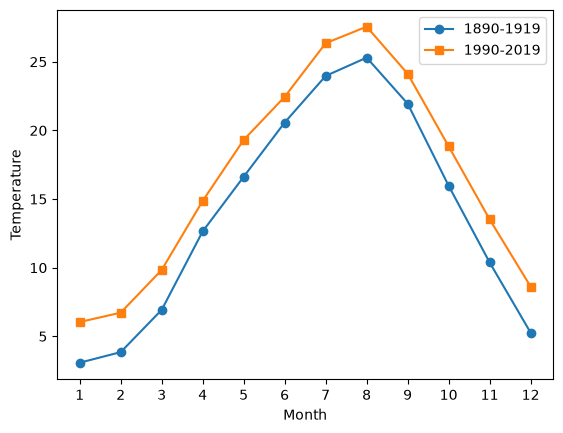

In [14]:
# A
import numpy as np
import matplotlib.pyplot as plt

tokyo_temp = np.genfromtxt("Tokyo_temp.csv",
                           delimiter=",",
                           usecols=(0, 1, 2)
                          )
y = tokyo_temp[:, 0]
m = tokyo_temp[:, 1]
temp = tokyo_temp[:, 2]

# 按要求的年份提取数据
temp_old = temp[(1890 <= y)*(y <= 1919)]
temp_new = temp[(1990 <= y)*(y <= 2019)]
m_old = m[(1890 <= y)*(y <= 1919)]
m_new = m[(1990 <= y)*(y <= 2019)]

month = np.arange(1, 13, 1)
temp_old_clim = np.zeros(12) # 初始化数组
temp_new_clim = np.zeros(12) 
for mm in range(1, 13):
    temp_old_clim[mm-1] = np.nanmean(temp_old[m_old==mm])
    temp_new_clim[mm-1] = np.nanmean(temp_new[m_new==mm])

plt.plot(month, temp_old_clim, label='1890-1919', marker='o')
# 如果在此处写了plt.show()，那么会生成两张图
plt.plot(month, temp_new_clim, label='1990-2019', marker='s')
plt.xticks(month)
plt.xlabel('Month')
plt.ylabel('Temperature')
plt.legend() # 抓取预先设定的label参数，将标签和颜色匹配，在空白位置生成标签
plt.show() # 生成一张空白画布，然后将这句上面的所有指令都整合到这张画布上

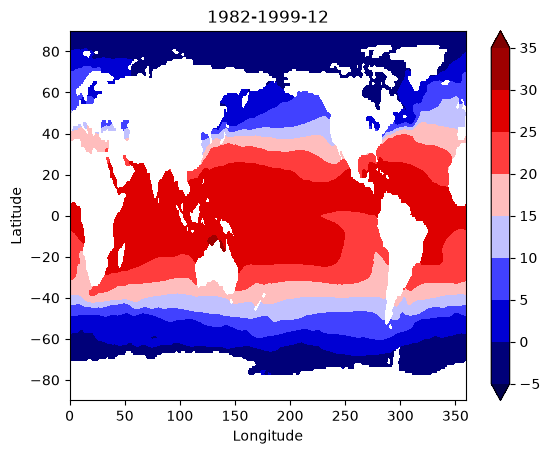

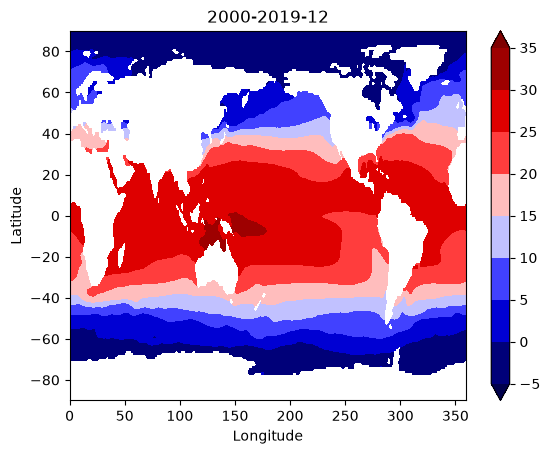

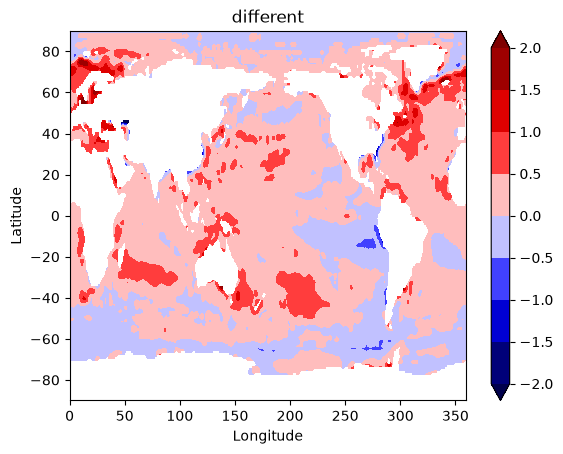

In [31]:
# B
import numpy as np
import matplotlib.pyplot as plt 
from matplotlib.colors import Normalize

loadfile = 'sst_OISST.npz'
sst_dataset = np.load(loadfile)

y = sst_dataset['y']
m = sst_dataset['m']
sst = sst_dataset['sst']
lon2 = sst_dataset['lon2']
lat2 = sst_dataset['lat2']

m_old = m[(1982 <= y)*(y <= 1999)]
m_new = m[(2000 <= y)*(y <= 2019)]
sst_old = sst[:, :, (1982 <= y)*(y <= 1999)]
sst_new = sst[:, :, (2000 <= y)*(y <= 2019)]

[imt, jmt, tmt] = sst.shape
sst_clim_old = np.zeros((imt, jmt, 12))
sst_clim_new = np.zeros((imt, jmt, 12))
sst_clim_diff = np.zeros((imt, jmt, 12))

sst_clim_old[:, :, 11] = np.mean(sst_old[:, :, m_old==12], 2)
sst_clim_new[:, :, 11] = np.mean(sst_new[:, :, m_new==12], 2)
sst_clim_diff[:, :, 11] = sst_clim_new[:, :, 11] - sst_clim_old[:, :, 11]

vmin = -5
vmax = 35
vint = 5

cm = plt.get_cmap('seismic')
cs_old = plt.contourf(lon2, lat2, sst_clim_old[:, :, 11], \
                  cmap=cm, norm=Normalize(vmin=vmin, vmax=vmax),\
                  levels=np.arange(vmin,vmax+vint,vint), extend='both')
plt.colorbar(cs_old)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
clim_title_old = '1982-1999-12'
plt.title(clim_title_old)
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.show()

plt.figure() # 每次画新的图之前都需要新建画布
cs_new = plt.contourf(lon2, lat2, sst_clim_new[:, :, 11], \
                  cmap=cm, norm=Normalize(vmin=vmin, vmax=vmax),\
                  levels=np.arange(vmin,vmax+vint,vint), extend='both')
plt.colorbar(cs_new)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
clim_title_new = '2000-2019-12'
plt.title(clim_title_new)
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.show()

plt.figure() 
vmin = -2
vmax = 2
vint = 0.5
cs_diff = plt.contourf(lon2, lat2, sst_clim_diff[:, :, 11], \
                  cmap=cm, norm=Normalize(vmin=vmin, vmax=vmax),\
                  levels=np.arange(vmin,vmax+vint,vint), extend='both')
plt.colorbar(cs_diff)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
clim_title_new = 'different'
plt.title(clim_title_new)
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.show()

